# Import Libraries

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

## Load Dataset

In [2]:
data_path = "C:\\Users\\PC\\Desktop\\Disease-Prediction-ML\\dataset\\Final_Augmented_dataset_Diseases_and_Symptoms.csv"

df = pd.read_csv(data_path)

print("Dataset loaded successfully!")

Dataset loaded successfully!


## View Dataset

In [6]:
df.head()

,diseases,anxiety and nervousness,depression,shortness of breath,depressive or psychotic symptoms,sharp chest pain,dizziness,insomnia,abnormal involuntary movements,chest tightness,...,stuttering or stammering,problems with orgasm,nose deformity,lump over jaw,sore in nose,hip weakness,back swelling,ankle stiffness or tightness,ankle weakness,neck weakness
0,panic disorder,1,0,1,1,0,0,0,0,1,...,0,0,0,0,0,0,0,0,0,0
1,panic disorder,0,0,1,1,0,1,1,0,0,...,0,0,0,0,0,0,0,0,0,0
2,panic disorder,1,1,1,1,0,1,1,0,0,...,0,0,0,0,0,0,0,0,0,0
3,panic disorder,1,0,0,1,0,1,1,1,0,...,0,0,0,0,0,0,0,0,0,0
4,panic disorder,1,1,0,0,0,0,1,1,1,...,0,0,0,0,0,0,0,0,0,0


## Dataset Shape

In [7]:
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])

Rows: 246945
Columns: 378


## Dataset Columns

In [8]:
print(df.columns.tolist())

['diseases', 'anxiety and nervousness', 'depression', 'shortness of breath', 'depressive or psychotic symptoms', 'sharp chest pain', 'dizziness', 'insomnia', 'abnormal involuntary movements', 'chest tightness', 'palpitations', 'irregular heartbeat', 'breathing fast', 'hoarse voice', 'sore throat', 'difficulty speaking', 'cough', 'nasal congestion', 'throat swelling', 'diminished hearing', 'lump in throat', 'throat feels tight', 'difficulty in swallowing', 'skin swelling', 'retention of urine', 'groin mass', 'leg pain', 'hip pain', 'suprapubic pain', 'blood in stool', 'lack of growth', 'emotional symptoms', 'elbow weakness', 'back weakness', 'pus in sputum', 'symptoms of the scrotum and testes', 'swelling of scrotum', 'pain in testicles', 'flatulence', 'pus draining from ear', 'jaundice', 'mass in scrotum', 'white discharge from eye', 'irritable infant', 'abusing alcohol', 'fainting', 'hostile behavior', 'drug abuse', 'sharp abdominal pain', 'feeling ill', 'vomiting', 'headache', 'nause

## Dataset Information

In [9]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 246945 entries, 0 to 246944
Columns: 378 entries, diseases to neck weakness
dtypes: int64(377), str(1)
memory usage: 716.3 MB


## Missing Values

In [10]:
missing_values = df.isnull().sum().sum()

print("Total missing values:", missing_values)

Total missing values: 0


## Duplicate Records

In [11]:
duplicate_count = df.duplicated().sum()

print("Duplicate rows:", duplicate_count)

Duplicate rows: 57298


## Separate Features and Target

In [12]:
X = df.drop("diseases", axis=1)
y = df["diseases"]

print("Features:", X.shape)
print("Target:", y.shape)

Features: (246945, 377)
Target: (246945,)


In [13]:
## Number of Diseases

In [14]:
number_of_diseases = y.nunique()

print("Number of diseases:", number_of_diseases)

Number of diseases: 773


## Disease Distribution

In [15]:
disease_counts = y.value_counts()

print(disease_counts.head(20))

diseases
cystitis                          1219
vulvodynia                        1218
nose disorder                     1218
complex regional pain syndrome    1217
spondylosis                       1216
hypoglycemia                      1215
conjunctivitis due to allergy     1215
vaginal cyst                      1215
esophagitis                       1215
peripheral nerve disorder         1215
gastrointestinal hemorrhage       1214
diverticulitis                    1214
acute bronchitis                  1213
infectious gastroenteritis        1212
pneumonia                         1212
fungal infection of the hair      1212
sprain or strain                  1212
spontaneous abortion              1212
gout                              1211
marijuana abuse                   1210
Name: count, dtype: int64


## Disease Statistics

In [16]:
print("Maximum samples:", disease_counts.max())
print("Minimum samples:", disease_counts.min())
print("Average samples:", round(disease_counts.mean(), 2))
print("Median samples:", disease_counts.median())

Maximum samples: 1219
Minimum samples: 1
Average samples: 319.46
Median samples: 168.0


## Top 20 Diseases

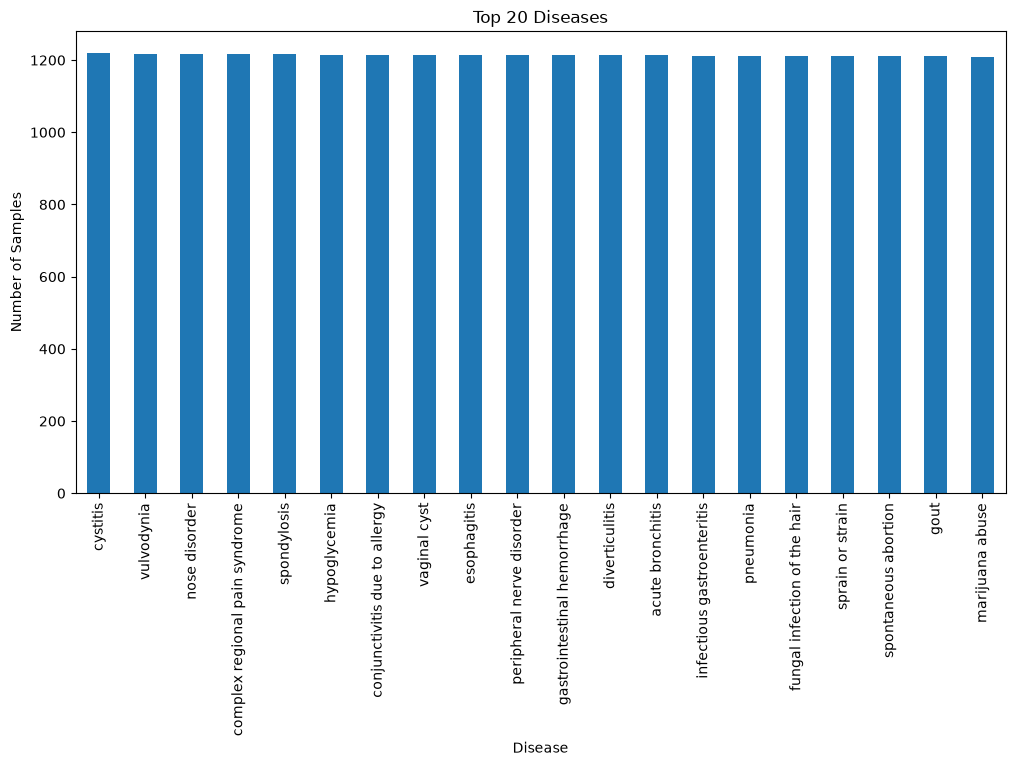

In [17]:
plt.figure(figsize=(12, 6))

disease_counts.head(20).plot(kind="bar")

plt.title("Top 20 Diseases")
plt.xlabel("Disease")
plt.ylabel("Number of Samples")
plt.xticks(rotation=90)

plt.show()

## Check Symptom Values

In [18]:
unique_values = pd.unique(X.values.ravel())

print("Unique feature values:", unique_values)

Unique feature values: [1 0]


## Check Binary Features

In [19]:
non_binary_columns = []

for column in X.columns:
    values = X[column].dropna().unique()

    if not set(values).issubset({0, 1}):
        non_binary_columns.append(column)

print("Non-binary columns:", len(non_binary_columns))

Non-binary columns: 0


## Check Symptom Patterns

In [ ]:
X_pattern = X.astype(str).agg("".join, axis=1)

print("Unique symptom patterns:", X_pattern.nunique())

## Check Conflicting Patterns

In [ ]:
pattern_disease_counts = (
    pd.DataFrame({
        "pattern": X_pattern,
        "disease": y.values
    })
    .groupby("pattern")["disease"]
    .nunique()
)

conflicting_patterns = pattern_disease_counts[
    pattern_disease_counts > 1
]

print("Conflicting symptom patterns:", len(conflicting_patterns))

Conflicting symptom patterns: 12634


# Data Cleaning

## Create Clean Dataset

In [ ]:
df_clean = df.copy()

print("Original shape:", df_clean.shape)

Original shape: (246945, 378)


## Remove Duplicate Records

In [ ]:
before = len(df_clean)

df_clean = df_clean.drop_duplicates().reset_index(drop=True)

after = len(df_clean)

print("Rows before:", before)
print("Rows after:", after)
print("Duplicates removed:", before - after)

Rows before: 246945
Rows after: 189647
Duplicates removed: 57298


## Verify Duplicates

In [ ]:
print("Remaining duplicates:", df_clean.duplicated().sum())

Remaining duplicates: 0


## Prepare Features and Target

In [ ]:
X = df_clean.drop("diseases", axis=1)
y = df_clean["diseases"]

print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (189647, 377)
y shape: (189647,)


## Check Rare Diseases

In [ ]:
disease_counts = y.value_counts()

rare_diseases = disease_counts[disease_counts < 2]

print("Diseases with only 1 sample:", len(rare_diseases))
print(rare_diseases)

Diseases with only 1 sample: 46
diseases
turner syndrome                                 1
hashimoto thyroiditis                           1
dengue fever                                    1
cryptococcosis                                  1
pulmonic valve disease                          1
diabetes                                        1
open wound of the chest                         1
huntington disease                              1
insulin overdose                                1
scurvy                                          1
omphalitis                                      1
adrenal cancer                                  1
esophageal varices                              1
vitamin a deficiency                            1
hypergammaglobulinemia                          1
diabetic kidney disease                         1
open wound of the cheek                         1
open wound of the knee                          1
vacterl syndrome                                1
typhoid f

## Save Clean Dataset

In [ ]:
clean_path = "C:\\Users\\PC\\Desktop\\Disease-Prediction-ML\\dataset\\cleaned_disease_dataset.csv"

df_clean.to_csv(clean_path, index=False)

print("Cleaned dataset saved successfully!")

Cleaned dataset saved successfully!
